In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel(
    r"C:\Users\MTC\Desktop\RetailPulse\data\processed\retail_clean.xlsx"
)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [3]:
# Creating KPIs for the EDA

total_revenue = df["Revenue"].sum()

total_quantity = df["Quantity"].sum()

unique_customers = df["Customer ID"].nunique()

unique_products = df["StockCode"].nunique()

total_transactions = df["Invoice"].nunique()

unique_invoices = df["Invoice"].nunique()


In [4]:
print("Total Revenue:", total_revenue)
print("Total Quantity:", total_quantity)
print("Unique Customers:", unique_customers)
print("Unique Products:", unique_products)
print("Transactions:", total_transactions)
print("Unique Invoices:", unique_invoices)

Total Revenue: 9726024.953999998
Total Quantity: 5162503
Unique Customers: 4372
Unique Products: 4070
Transactions: 25900
Unique Invoices: 25900


In [17]:
monthly_revenue = (
    df.groupby("YearMonth")["Revenue"]
    .sum()
)

print(monthly_revenue)

YearMonth
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722094.100
2011-06     689977.230
2011-07     680156.991
2011-08     681386.460
2011-09    1017596.682
2011-10    1069368.230
2011-11    1456145.800
2011-12     432719.060
Name: Revenue, dtype: float64


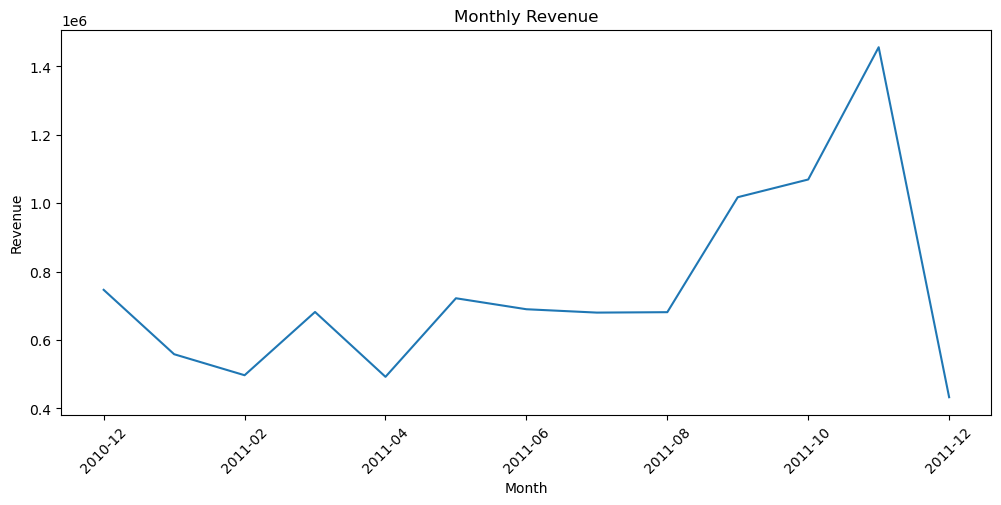

In [6]:
monthly_revenue.plot(figsize=(12, 5))

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

In [7]:
top_products = (
    df.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

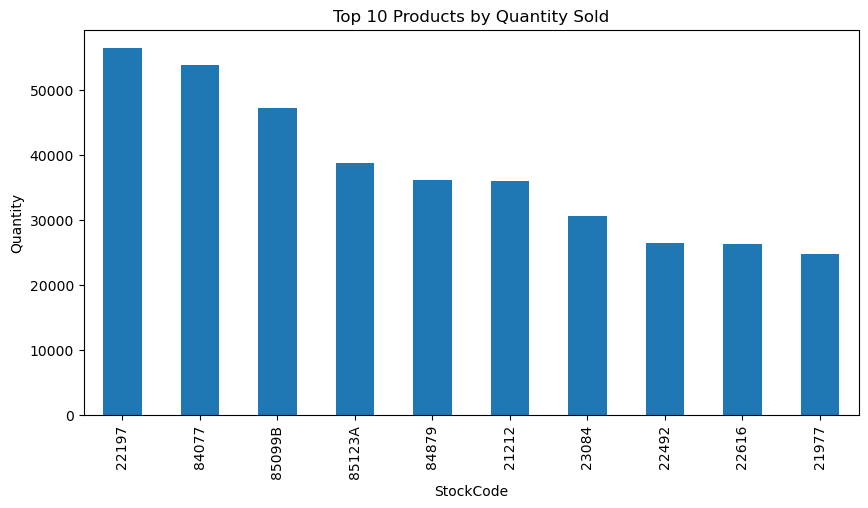

In [8]:
top_products.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("StockCode")
plt.ylabel("Quantity")
plt.show()

In [18]:
country_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(country_revenue)

Country
United Kingdom    8167128.184
Netherlands        284661.540
EIRE               262993.380
Germany            221509.470
France             197335.110
Australia          137009.770
Switzerland         56363.050
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: Revenue, dtype: float64


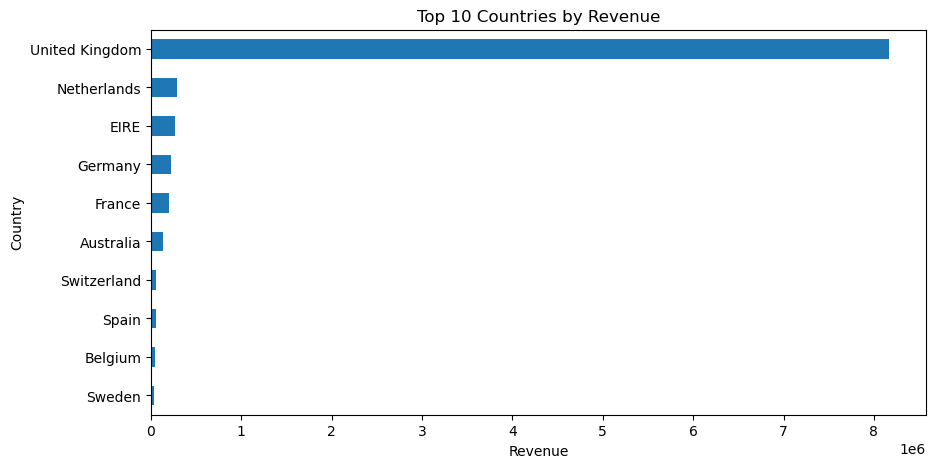

In [27]:
plt.figure(figsize=(10, 5))

country_revenue.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.show()

In [10]:
customer_revenue = (
    df.dropna(subset=["Customer ID"])
    .groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

In [11]:
returns = df[df["Quantity"] < 0]

print("Return/negative quantity records:", len(returns))

return_by_product = (
    returns.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values()
    .head(10)
)

Return/negative quantity records: 10587


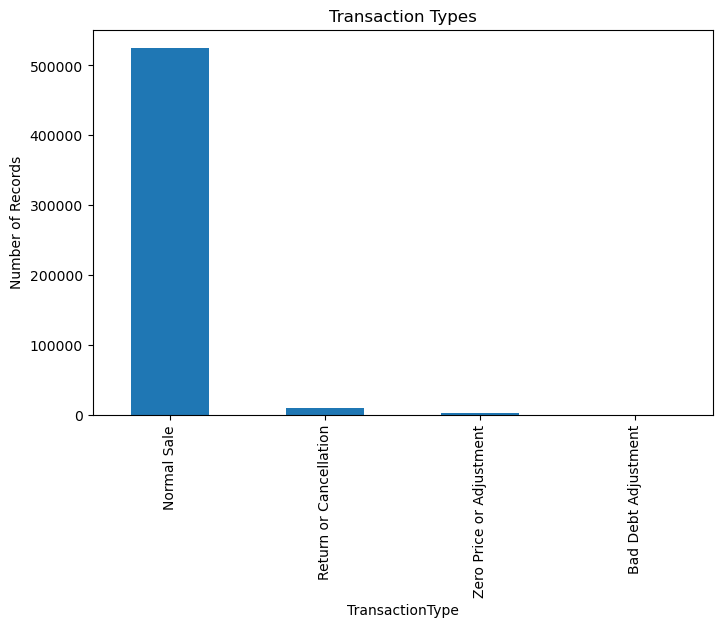

In [12]:
df["TransactionType"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Transaction Types")
plt.ylabel("Number of Records")
plt.show()

In [21]:
sales = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

In [22]:
top_products_revenue = (
    sales.groupby("StockCode")["Revenue"]
         .sum()
         .sort_values(ascending=False)
         .head(10)
)

In [48]:
top_products_quantity = (
    sales.groupby("StockCode")["Quantity"]
         .sum()
         .sort_values(ascending=False)
         .head(10)
)

print(top_products_quantity)

StockCode
23843     80995
23166     78033
22197     56898
84077     54951
85099B    48371
85123A    37641
21212     36396
84879     36362
23084     30739
22492     26633
Name: Quantity, dtype: int64


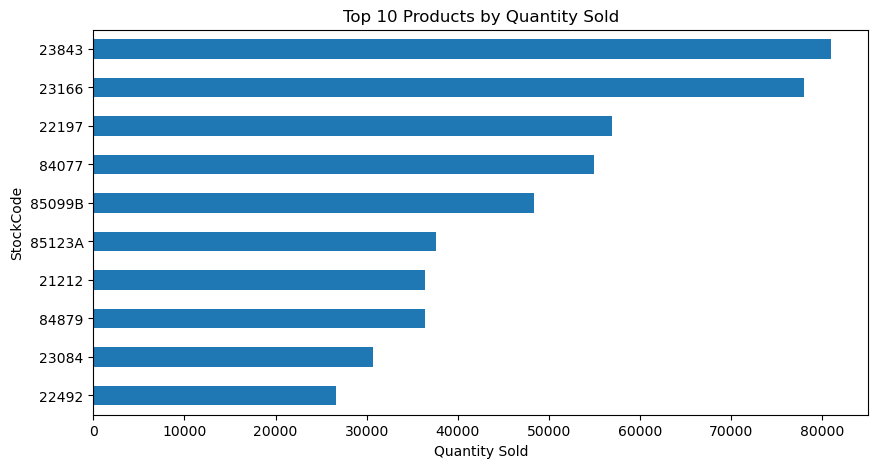

In [24]:
plt.figure(figsize=(10, 5))

top_products_quantity.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("StockCode")

plt.show()

In [46]:
top_products_revenue = (
    sales.groupby("StockCode")["Revenue"]
         .sum()
         .sort_values(ascending=False)
         .head(10)
)

print(top_products_revenue)

StockCode
DOT       206248.77
22423     174156.54
23843     168469.60
85123A    104462.75
47566      99445.23
85099B     94159.81
23166      81700.92
POST       78119.88
M          77750.27
23084      66870.03
Name: Revenue, dtype: float64


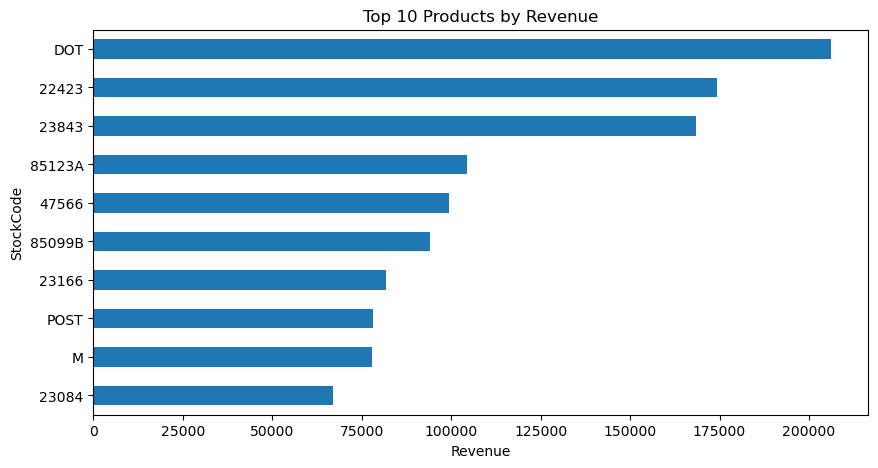

In [26]:
plt.figure(figsize=(10, 5))

top_products_revenue.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("StockCode")

plt.show()

In [28]:
customer_sales = sales.dropna(
    subset=["Customer ID"]
)

In [29]:
customer_revenue = (
    customer_sales
    .groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

In [31]:
customer_revenue.head(5)

Customer ID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
Name: Revenue, dtype: float64

In [32]:
customer_revenue.describe()


count      4338.000000
mean       2048.692230
std        8985.229676
min           3.750000
25%         306.482500
50%         668.570000
75%        1660.597500
max      280206.020000
Name: Revenue, dtype: float64

In [34]:
returns = df[
    df["Quantity"] < 0
].copy()

print("Return/negative quantity records:", len(returns))

Return/negative quantity records: 10587


In [37]:
total_returns = abs(
    returns["Quantity"].sum()
)

print("Total returned quantity:", total_returns)

return_rate = (
    len(returns) /
    len(df)
) * 100

print("Return record rate:", round(return_rate, 2), "%")

Total returned quantity: 482517
Return record rate: 1.97 %


In [38]:
weekday_sales = (
    sales.groupby("DayOfWeek")["Revenue"]
         .sum()
)

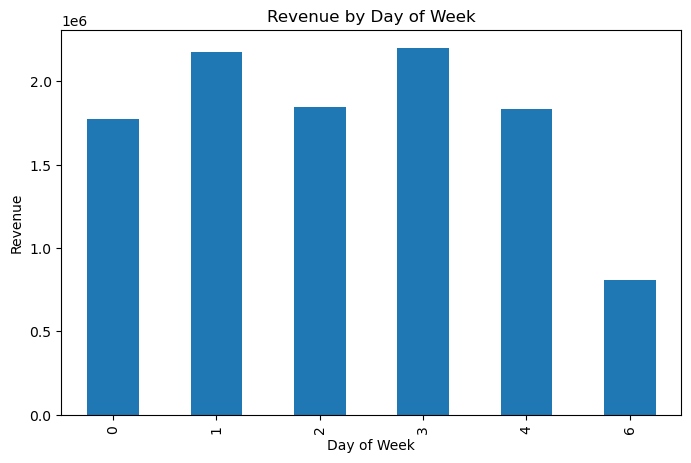

In [39]:
plt.figure(figsize=(8, 5))

weekday_sales.plot(kind="bar")

plt.title("Revenue by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Revenue")

plt.show()

In [40]:
# Product summary statistics

product_summary = (
    sales.groupby("StockCode")
    .agg(
        TotalQuantity=("Quantity", "sum"),
        TotalRevenue=("Revenue", "sum"),
        AveragePrice=("Price", "mean"),
        NumberOfTransactions=("Invoice", "nunique")
    )
    .sort_values(
        "TotalRevenue",
        ascending=False
    )
)

In [41]:
product_summary.head(10)

,TotalQuantity,TotalRevenue,AveragePrice,NumberOfTransactions
StockCode,,,,
DOT,706,206248.77,292.137068,706
22423,13851,174156.54,13.983936,1988
23843,80995,168469.60,2.080000,1
85123A,37641,104462.75,3.117838,2198
47566,18283,99445.23,5.797928,1685
85099B,48371,94159.81,2.486197,2089
23166,78033,81700.92,1.468480,247
POST,3151,78119.88,31.064978,1127
M,6984,77750.27,234.489652,289


### Co-relation analysis


In [42]:
numeric_columns = [
    "Quantity",
    "Price",
    "Revenue"
]

correlation = df[
    numeric_columns
].corr()

correlation

,Quantity,Price,Revenue
Quantity,1.000000,-0.001241,0.886712
Price,-0.001241,1.000000,-0.162043
Revenue,0.886712,-0.162043,1.000000


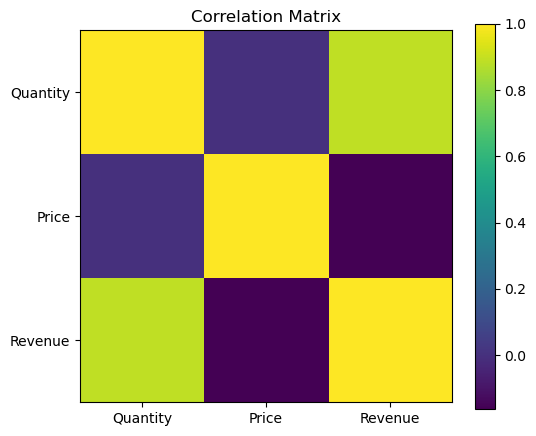

In [43]:
plt.figure(figsize=(6, 5))

plt.imshow(correlation)

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.colorbar()

plt.title("Correlation Matrix")

plt.show()

In [44]:
monthly_pattern = (
    sales.groupby(
        sales["InvoiceDate"].dt.month
    )["Revenue"]
    .mean()
)

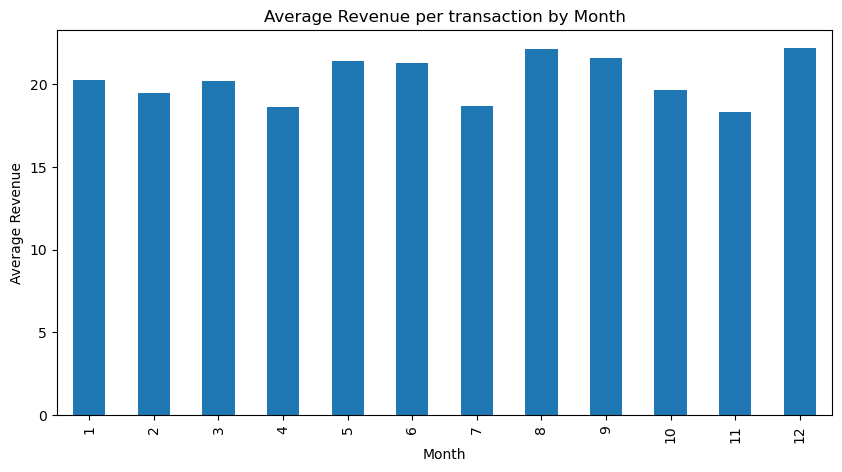

In [49]:
plt.figure(figsize=(10, 5))

monthly_pattern.plot(
    kind="bar"
)

plt.title("Average Revenue per transaction by Month")
plt.xlabel("Month")
plt.ylabel("Average Revenue")

plt.show()

### Key EDA Findings

1. Revenue Trend:
   Monthly revenue shows considerable variation over time, with a strong increase during the later months of 2011. Revenue reaches its highest level around November 2011, followed by a sharp decline in December.

2. Top products by quantity (Stockcode - Quantity):
   (23843 - 80995), (23166 - 78033), (22197 - 56898)

3. Top products by Revenue (Stockcode - Revenue): 
   (DOT- 206248.77), (22423 - 174156.54), (23843 - 168469.60)

4. Top Countries - United Kingdom    8167128.184
                   Netherlands        284661.540
                   EIRE               262993.380
                   Germany            221509.470

5. Customer behaviour:
   Customer spending varies considerably, with a smaller group of customers contributing a large amount of revenue.
   
6. Return behavior:
   Negative-quantity transactions represent returns/cancellations and other adjustments, so they need to be treated separately from normal sales.

7. Transaction types:
   Most transactions are normal sales, while returns, zero-price adjustments, and bad-debt adjustments form smaller transaction groups.

8. Seasonal patterns:
   Average revenue varies across calendar months, suggesting possible monthly patterns that should be investigated further.

9. Important observations for forecasting:
   Revenue and quantity show noticeable variation over time, making historical demand patterns useful for forecasting future demand.

10. Important observations for customer segmentation:
    Customer purchase frequency, recency, and spending vary significantly, making RFM-based customer segmentation suitable.